# Lesson 13 pre-class prep: Reprojecting and merging

Before class, make sure you can import the data we will use in [lesson 13](https://meds-eds-220.github.io/MEDS-eds-220-course/book/chapters/lesson-12-merge-data/lesson-12-merge-data.html). Run the four code cells in this notebook. If they all run without errors, you are ready for class!

## About the data

We will use three datasets:

1. **Arctic communities**: a GeoJSON file with the [list of Arctic communities and their location](https://search.dataone.org/view/doi%3A10.18739%2FA28S4JQ80), created by the [Alaska Native Tribal Health Consortium](https://www.anthc.org). We will read it directly from its URL, so you don't need to download it.

2. **Countries**: [Natural Earth's medium-scale cultural boundaries data for countries (1:50m)](https://www.naturalearthdata.com/downloads/50m-cultural-vectors/). [Natural Earth](https://www.naturalearthdata.com) is a public domain dataset with free, ready-to-use data for creating maps. To download it:
    1. Go to the [Natural Earth 1:50m cultural vectors page](https://www.naturalearthdata.com/downloads/50m-cultural-vectors/).
    2. Under "Admin 0 – Countries", click on "Download countries".
    3. Unzip the file and move the `ne_50m_admin_0_countries` folder into a `data/` folder at the same level as this notebook.

3. **Country names**: a CSV with the country codes and names of the Arctic countries in the Arctic communities dataset. It was created for this lesson from the metadata of the Arctic communities dataset and the country names in Natural Earth's dataset. We will read it directly from its URL, so you don't need to download it.

Read the information about the datasets in the [lesson](https://meds-eds-220.github.io/MEDS-eds-220-course/book/chapters/lesson-12-merge-data/lesson-12-merge-data.html) before class.

## Import libraries

In [22]:
import os

import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

## Import countries shapefile

In [23]:
fp = os.path.join('data', 'ne_50m_admin_0_countries', 'ne_50m_admin_0_countries.shp')
countries = gpd.read_file(fp)

# Simplify column names
countries.columns = countries.columns.str.lower()

# Select columns for analysis
countries = countries[['admin', 'type', 'geometry']]

countries.head(3)

,admin,type,geometry
0,Zimbabwe,Sovereign country,"POLYGON ((31.28789 -22.40205, 31.19727 -22.344..."
1,Zambia,Sovereign country,"POLYGON ((30.39609 -15.64307, 30.25068 -15.643..."
2,Yemen,Sovereign country,"MULTIPOLYGON (((53.08564 16.64839, 52.58145 16..."


## Import Arctic communities data

In [24]:
URL = 'https://cn.dataone.org/cn/v2/resolve/urn%3Auuid%3Aed7718ae-fb0d-43dd-9270-fbfe80bfc7a4'
communities = gpd.read_file(URL)

communities.head(3)

,name,population,country,geoname-id,geometry
0,Udomlya,32373,RU,452949,POINT (34.99250 57.87944)
1,Valmiera,26963,LV,453754,POINT (25.42751 57.54108)
2,Ventspils,42644,LV,454310,POINT (21.57288 57.38988)


## Import country names CSV

In [25]:
URL = 'https://raw.githubusercontent.com/MEDS-eds-220/MEDS-eds-220-course/refs/heads/main/book/chapters/lesson-12-merge-data/country_names.csv'
country_names = pd.read_csv(URL)

country_names.head(3)

,country,admin
0,RU,Russia
1,LV,Latvia
2,EE,Estonia


In [26]:
print(countries.crs)

EPSG:4326


In [27]:
assert countries.crs == communities.crs

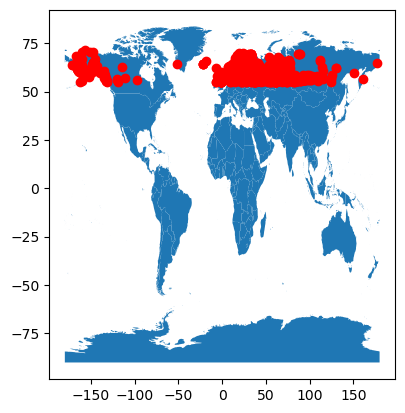

In [28]:
fig, ax = plt.subplots()

countries.plot(ax=ax)
communities.plot(ax=ax, color='red')
plt.show()

## Arctic Communities by Country

We want to calculate the number of Arctic communities in each country.

In [29]:
# Create dataframe with number of communites by country
n_comms = communities.groupby('country').size().reset_index(name = 'n_communities')

Goal: merge the `n_comms` and  `countries` dataframes.

To merge two dataframes, they need to have at least one column in common. Do they ??

In [30]:
set(countries.columns).intersection(n_comms.columns)

set()

In [31]:
common_columns = set(countries.columns).intersection(n_comms.columns)

# Check if there are any common columns

if len(common_columns) !=0:
    print(f"Common columns: {common_columns}")
else: 
    print("No common columns")

No common columns


### Check-in:
Make the previous code into a function called `check_common_columns`, that takes in two data frames as arguements.

In [32]:
def check_common_columns(df1, df2):

    common_columns = set(df1.columns).intersection(df2.columns)

    if len(common_columns) !=0:
        print(f"Common columns: {common_columns}")
    else: 
        print("No common columns")

    return

In [33]:
check_common_columns(n_comms, countries)

No common columns


## Merge dataframes

We can use the country_names data frame to add the country names into the `n_comms` data which, in turn, will allow us to merge that data frame with the `countries` data. 

To merge data frames we can use the `pandas.merge()` function. The basic syntax for it is:

```python
output_df = pd.merge(left_df,
                    right_df,
                    how = type_of_join,
                    on = column_to_join)
```

Where:

- `output_df` = df resulting from merge
- `left_df` = df we hace on the left side
- `right_df` = df we hace on the right side
- `how` = type of join
- `on` = column to join on, must be present in both dataframes

In [34]:
n_comms = pd.merge(n_comms,
                   country_names,
                   how='left',
                   on='country')
n_comms

,country,n_communities,admin
0,AX,1,Aland Islands
1,BY,8,Belarus
2,CA,7,Canada
3,DK,72,Denmark
4,EE,14,Estonia
5,FI,98,Finland
6,FO,1,Faroe Islands
7,GB,96,United Kingdom
8,GL,1,Greenland
9,IS,5,Iceland


In [35]:
check_common_columns(n_comms, countries)

Common columns: {'admin'}


### Check-in

Create a new variable named `arctic_countries` which is the result of an **inner join** between our `countries` and `n_comms` data frames. The inner join will merge the subset of rows that have matches in both the left table and the right table.

![alt text](https://meds-eds-220.github.io/MEDS-eds-220-course/book/images/merging_data/join-diagrams-inner.png)

#### **Note!** When merging geoDataFrames in Python you must ALWAYS keep the geoDataFrame on the **LEFT** or the geometry will be *dropped*.


In [ ]:
arctic_countries = n_comms.merge(countries,
                                   how = 'inner',
                                   on = 'admin')
arctic_countries

,country,n_communities,admin,type,geometry
0,BY,8,Belarus,Sovereign country,"POLYGON ((31.76338 52.10107, 31.57373 52.10811..."
1,CA,7,Canada,Sovereign country,"MULTIPOLYGON (((-132.65552 54.12749, -132.5640..."
2,DK,72,Denmark,Country,"MULTIPOLYGON (((12.56875 55.78506, 12.57119 55..."
3,EE,14,Estonia,Sovereign country,"MULTIPOLYGON (((27.35195 57.52812, 27.32656 57..."
4,FI,98,Finland,Country,"MULTIPOLYGON (((24.15547 65.80527, 24.04902 65..."
5,FO,1,Faroe Islands,Dependency,"MULTIPOLYGON (((-6.62319 61.80596, -6.64277 61..."
6,GB,96,United Kingdom,Country,"MULTIPOLYGON (((-2.66768 51.62300, -2.74214 51..."
7,GL,1,Greenland,Country,"MULTIPOLYGON (((-29.95288 83.56484, -28.99199 ..."
8,IS,5,Iceland,Sovereign country,"POLYGON ((-15.54312 66.22852, -15.42847 66.224..."
9,LT,26,Lithuania,Sovereign country,"MULTIPOLYGON (((20.95781 55.27891, 20.89980 55..."


## Reviewing results

It is always a good idea to check the number of rows after a merge. Our `n_comms` data frame has one row per country, but the merged data frame has one row less:



In [43]:
print(f"Countries in n_comms: {len(n_comms)}")
print(f"Countries in arctic_countries: {len(arctic_countries)}")

Countries in n_comms: 16
Countries in arctic_countries: 15


An inner join only keeps the rows that have a match in both data frames, so one country in `n_comms` had no match in `countries`. We can find it using `isin()`:

In [44]:
# Countries in n_comms without a match in countries
n_comms[~n_comms['admin'].isin(countries['admin'])]
# ~ returns opposite, aka, "it is not"

,country,n_communities,admin
0,AX,1,Aland Islands


The Aland Islands are an autonomous region of Finland and there is one Arctic community registered in this region. Like the Faroe Islands and Greenland, the Aland Islands have their own country code in the Arctic communities data and their own polygon in Natural Earth’s data. So why didn’t they match? Let’s look for them in the `countries` data frame:



In [45]:
countries[countries['admin'].str.contains('Aland')]

,admin,type,geometry
168,Aland,Country,"MULTIPOLYGON (((19.98955 60.35117, 20.02021 60..."


Natural Earth’s data calls this region ‘Aland’, while our `country_names` data uses ‘Aland Islands’. The values in the column we join on must match exactly for the merge to find them. We update the name in `n_comms` to match the `countries` data and merge again:



In [46]:
# Match the name used in the countries data
n_comms['admin'] = n_comms['admin'].replace('Aland Islands', 'Aland')

# Merge again
arctic_countries = countries.merge(n_comms,
                                   how='inner',
                                   on='admin')
print(f"Countries in arctic_countries: {len(arctic_countries)}")

Countries in arctic_countries: 16


### Checking with `indicator=True`

Another way to find rows without a match is to add `indicator=True` to the merge. This creates a `_merge` column that says whether each row was found in both data frames or only in one of them:



In [47]:
left = pd.DataFrame({'key': ['a', 'b', 'c'], 'x': [1, 2, 3]})
right = pd.DataFrame({'key': ['a', 'b', 'd'], 'y': [4, 5, 6]})

pd.merge(left, right, how='outer', on='key', indicator=True)

,key,x,y,_merge
0,a,1.0,4.0,both
1,b,2.0,5.0,both
2,c,3.0,NaN,left_only
3,d,NaN,6.0,right_only


## Chloropleth Map

Making a choropleth map from our polygons GeoDataFrame is easy; we just need to specify the column parameter in plot() and make it equal to the column with the values we want to plot in each country:

<Axes: >

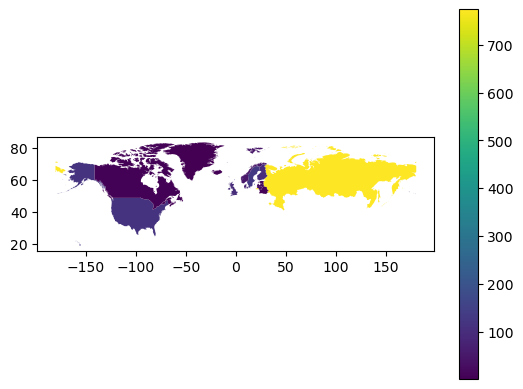

In [48]:
arctic_countries.plot(column='n_communities',
                      legend=True)

## Reprojecting

In [52]:
# Reproject to CRS optimized for Arctic region
arctic_countries_reproject = arctic_countries.to_crs('EPSG:3413')
arctic_countries_reproject.crs

<Projected CRS: EPSG:3413>
Name: WGS 84 / NSIDC Sea Ice Polar Stereographic North
Axis Info [cartesian]:
- X[south]: Easting (metre)
- Y[south]: Northing (metre)
Area of Use:
- name: Northern hemisphere - north of 60°N onshore and offshore, including Arctic.
- bounds: (-180.0, 60.0, 180.0, 90.0)
Coordinate Operation:
- name: US NSIDC Sea Ice polar stereographic north
- method: Polar Stereographic (variant B)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

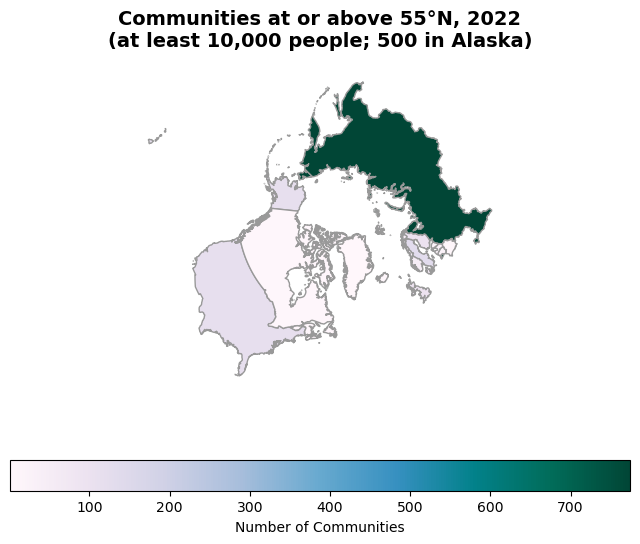

In [ ]:
fig, ax = plt.subplots(figsize=(8,6))

ax.axis('off')



arctic_countries_reproject.plot(ax=ax,
                                column='n_communities',
                                legend=True,
                                edgecolor = "0.6",
                                cmap = 'PuBuGn',
                                legend_kwds ={
                                    "label" : "Number of Communities",
                                    "orientation" : "horizontal"
                                }
                                )
ax.set_title('Communities at or above 55°N, 2022\n(at least 10,000 people; 500 in Alaska)',
             fontsize=14, weight='bold', pad=15)

plt.show()